# 3_Smart-Kage: OiP analysis

OiP (Object in Place) take place the day after test day, where the two objects on test day are swapped to the opposite side on OiP day. To check whether your data include OiP, you can go to `NOR_data.csv` under the DB folder, if you see index '3' in the NOR design, such as 1,4,2,3,4, that means the fourth day is the OiP day. 

This notebook reads the master table that the analysis notebook already built
(`NOR_MASTER_<MASTER_NAME>/NOR_MASTER_binned.csv`). Therefore you should run the `SmartKages_NOR_postprocessing` and `SmartKages_NOR_analysis` to generate the master_binned.csv prior running this notebook. 


### **Please Note:
This notebook is built based on two OiP cohort (2025-07-July_OiP_CohortC and 2025-08-Aug_OiP_CohortD) where half of the kages underwent OiP whereas the other half didn't. 

**Sides are named from the test phase:** the *test novel side* is `NOR_side` (where the novel
object was in test), the *test familiar side* is the other one. OiP uses the same two objects as test:
- **unchanged OiP:** the two objects swap sides (the proper OiP), so in OiP the test-novel object
  is on the test familiar side
- **changed OiP:** both objects stay where they were in test


## Sections:
1. Settings
2. Load the master table
3. Align to the wheel change into OiP (2 h before, up to 24 h after)
4. Total exploration around the wheel change (2 h before; 2 h / 8 h / 24 h after)
5. Exploration of each side around the wheel change
6. Per-mouse totals: 2 h before vs 2 h / 8 h / 24 h after
7. Individual kages around the wheel change (four plot options)

**Nothing is saved unless `SAVE_OUTPUTS = True`** in the settings cell. Then figures (PDF) and
tables (CSV) go to `NOR_MASTER_<MASTER_NAME>/OiP_analysis/`.

## How to use:
- make sure you have the NOR_MASTER file ready
- change the settings below: You'll need to manually fill in what are the kages you would like to include in the analysis. As some kages may be used in NOR but not in OiP. Refer to your NOR QC note to decide if the kage could be included. 

In [131]:
import pandas as pd
import numpy as np
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

pd.set_option("display.max_columns", 100)

In [132]:
mpl.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "font.family": "Arial",
    "axes.grid": False,
    "font.size": 18,
    "axes.labelsize": 20,
    "axes.titlesize": 22,
    "xtick.labelsize": 17,
    "ytick.labelsize": 17,
    "legend.fontsize": 16,
    "axes.linewidth": 1.2,
    "savefig.transparent": True,
    "savefig.bbox": "tight",
})


def format_axes(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", direction="in", width=1.2, length=5, pad=6)
    ax.set_facecolor("white")
    return ax


def save_fig(fig, name):
    """Save a figure as PDF in OIP_OUTPUT, only when SAVE_OUTPUTS is True."""
    if SAVE_OUTPUTS:
        OIP_OUTPUT.mkdir(exist_ok=True)
        fig.savefig(OIP_OUTPUT / f"{name}.pdf", bbox_inches="tight")
        print("Saved:", OIP_OUTPUT / f"{name}.pdf")


def timepoint_label(minutes):
    return f"{minutes} min" if minutes < 60 else f"{minutes // 60} h"


def smooth(values, time_min, sigma=None):
    """Gaussian-smooth a line, separately before and after the wheel change (time 0).

    Smoothing each side on its own stops the burst at the wheel change from
    leaking into the minutes before it. sigma is in bins (default SMOOTH_SIGMA).
    """
    sigma = SMOOTH_SIGMA if sigma is None else sigma
    values = np.asarray(values, dtype=float)
    if sigma <= 0:
        return values
    out = values.copy()
    for part in (time_min < 0, time_min >= 0):
        if part.sum() > 1:
            out[part] = gaussian_filter1d(values[part], sigma=sigma)
    return out


def time_axis(after_min):
    """x scale (1 = minutes, 60 = hours), unit and ticks for a window ending after_min after the change."""
    if after_min <= 180:
        return 1, "min", np.arange(-BEFORE_MIN, after_min + 1, 60)
    after_h = after_min // 60
    step = 2 if after_h <= 8 else 4
    return 60, "h", [-BEFORE_MIN / 60, 0] + list(range(step, after_h + 1, step))


def panel_width(after_min):
    """Panel width (inches): longer windows get wider panels so the time axis is not squashed."""
    if after_min <= 180:
        return 9
    if after_min <= 480:
        return 16
    return 24

## 1. Settings

In [133]:
# BASE_DIR = Path("/Users/jiatongsun/SmartKages_OiP_processed")      # test cohort
BASE_DIR = Path("/Volumes/SWC_SmrtKg2/SmartKages_Nov2025_onwards")   # drive

MASTER_NAME = "RELN-COLBOS"
MASTER_OUTPUT = BASE_DIR / f"NOR_MASTER_{MASTER_NAME}"

# Which kages go into the OiP analysis (the OiP day only). Kages with NOR_good = no (days 1-3) are already
# missing from the master. One entry per cohort, because KageIDs repeat across cohorts.
# "kage1", "Kage1" and "kage 1" all work. Only kages in "include" are used; a kage in neither list is
# excluded and listed under "Check" in 2.1.

OIP_KAGES = {

    "new_2025-11-Nov-Dec_RELN-COLBOS_Coh1": {
        "include": ["Kage1", "Kage3", "Kage4", "Kage5", "Kage8", "Kage9" ],
        "exclude": ["Kage2", "Kage6", "Kage7"],   # mouse pulled the insert out of the wheel on OiP day
    },

    "2026-01-Jan-Feb_RELN-COLBOS_Coh2": {
        "include": ["Kage1","Kage2", "Kage3", "Kage4", "Kage5", "Kage8", "Kage9",
                 "Kage11", "Kage12", "Kage13", "Kage14", "Kage16"],
        "exclude": ["Kage6","Kage7", "Kage10",  "Kage15"],    # mouse pulled the insert out of the wheel on OiP day
    },
}



# Fill in the follwing variables accordingly based on the cohort information. 
AGE_ORDER = ["3m"]
GENO_ORDER = ["WT", "RELN-Colbos"]
GENO_COLORS = {
    "WT": "blue",
    "RELN-Colbos": "red",
}
SIDE_COLORS = {
    "test novel side": "#2E96C7",
    "test familiar side": "#F2908C",
}

TARGET_PHASE = "OiP"                  # wheel change to align on
BEFORE_MIN = 120                      # always show the last 2 h before the wheel change
AFTER_WINDOWS_MIN = [120, 480, 1440]  # plot 2 h, 8 h and 24 h after the wheel change
BIN_MIN = 1                           # plotting bin (minutes)
SMOOTH_SIGMA = 1.5                    # Gaussian smoothing of the time plots, in bins (0 = off)

SAVE_OUTPUTS = True   # True saves figures and tables to OIP_OUTPUT
OIP_OUTPUT = MASTER_OUTPUT / "OiP_analysis"

## 2. Load the master binned table

One row per mouse, phase and minute (`bin` = minutes since that phase's wheel change).

Columns added here:
- `test_novel_side_sec` / `test_familiar_side_sec`: exploration of `NOR_side` / the other side

In [134]:
binned_df = pd.read_csv(MASTER_OUTPUT / "NOR_MASTER_binned.csv")

for col in ["Age", "Genotype", "Phase", "KageID", "Cohort", "MouseSessionID", "NOR_side"]:
    binned_df[col] = binned_df[col].astype(str).str.strip()

binned_df["bin"] = pd.to_numeric(binned_df["bin"], errors="coerce")
binned_df = binned_df.dropna(subset=["bin"]).copy()
binned_df["bin"] = binned_df["bin"].astype(int)
binned_df["rotation"] = pd.to_datetime(binned_df["rotation"])
binned_df["bin_start"] = pd.to_datetime(binned_df["bin_start"])

# Exploration of each side, named relative to the test phase
test_novel_is_left = binned_df["NOR_side"].str.upper().str[0].eq("L")
binned_df["test_novel_side_sec"] = np.where(test_novel_is_left, binned_df["left_sec"], binned_df["right_sec"])
binned_df["test_familiar_side_sec"] = np.where(test_novel_is_left, binned_df["right_sec"], binned_df["left_sec"])

binned_all = binned_df.copy()   # every kage in the master; 2.1 filters binned_df from this, so 2.1 can be rerun

print("Phases:", binned_df["Phase"].value_counts().to_dict())

Phases: {'test': 29791, 'OiP': 29139, 'ITI_baseline': 28891, 'sample': 28837, 'pre_sample': 2400}


### 2.1 Kages included in OiP (`OIP_KAGES`)

One row per kage (in the master or in `OIP_KAGES`):
- `included in NOR`: passed NOR QC (`NOR_good` = yes), so it is in the master table
- `included in OiP`: used in this notebook (included in NOR and in the `"include"` list)
- `note`: empty when everything is fine; otherwise what to change in `OIP_KAGES`

After editing `OIP_KAGES`, rerun the settings cell, then this cell.

In [135]:
def kage_name(name):
    """'kage1', 'Kage1' and 'kage 1' all become 'Kage1'."""
    return str(name).strip().replace(" ", "").lower().replace("kage", "Kage")


def kage_number(kage_id):
    return int("0" + "".join(filter(str.isdigit, kage_id)))


include = {(c, kage_name(k)) for c, lists in OIP_KAGES.items() for k in lists.get("include", [])}
exclude = {(c, kage_name(k)) for c, lists in OIP_KAGES.items() for k in lists.get("exclude", [])}
in_nor = set(binned_all[["Cohort", "KageID"]].itertuples(index=False, name=None))
has_oip = set(binned_all.loc[binned_all["Phase"].eq(TARGET_PHASE), ["Cohort", "KageID"]].itertuples(index=False, name=None))
cohorts = {c for c, _ in in_nor}

# Kages used from here on (always filtered from binned_all, so this cell can be rerun)
included = (include - exclude) & in_nor
binned_df = binned_all[[(c, k) in included for c, k in zip(binned_all["Cohort"], binned_all["KageID"])]].copy()


def note(p):
    """What to change in OIP_KAGES for this kage ('' when nothing)."""
    if p in include and p in exclude:
        return "in both include and exclude lists: remove the kage from one"
    if p in in_nor and p not in include and p not in exclude:
        return "not in any include or exclude lists: add kage to one"
    if p in include and p not in in_nor:
        return "failed NOR QC but listed as include in OiP: move to exclude list"
    if p in included and p not in has_oip:
        return f"no {TARGET_PHASE} phase: move to exclude list"
    return ""


# One row per kage that is in the master or in OIP_KAGES (cohorts in this master only)
kages = sorted({p for p in include | exclude | in_nor if p[0] in cohorts}, key=lambda p: (p[0], kage_number(p[1])))
inclusion_table = pd.DataFrame({
    "Cohort": [c.split("_")[-1] for c, _ in kages],   # short name, e.g. 'Coh2'
    "KageID": [k for _, k in kages],
    "included in NOR": ["yes" if p in in_nor else "no" for p in kages],
    "included in OiP": ["yes" if p in included else "no" for p in kages],
    "note": [note(p) for p in kages],
})
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(inclusion_table)

n_notes = inclusion_table["note"].ne("").sum()
print(f"{n_notes} kage(s) to check: see the note column." if n_notes
      else "All kages are in include or exclude, and every included kage passed NOR QC.")

,Cohort,KageID,included in NOR,included in OiP,note
0,Coh2,Kage1,yes,yes,
1,Coh2,Kage2,yes,yes,
2,Coh2,Kage3,yes,yes,
3,Coh2,Kage4,yes,yes,
4,Coh2,Kage5,yes,yes,
5,Coh2,Kage6,yes,no,
6,Coh2,Kage7,no,no,
7,Coh2,Kage8,yes,yes,
8,Coh2,Kage9,yes,yes,
9,Coh2,Kage10,yes,no,


All kages are in include or exclude, and every included kage passed NOR QC.


### 2.2 Sanity Check: novel side for each kage

This cell prints out the following information:
- `NOR_side`: novel side in test, as written in `kage_descriptions.csv`
- `test_novel_side` / `test_familiar_side`: what this notebook calls the two sides (from `NOR_side`)
- `test_wheel_change` / `OiP_wheel_change`: clock time of each wheel change, and the video clip of that day
  (`<cohort>/NOR_video_check/`)
- `test_first_exploration` / `OiP_first_exploration`: exact time (0.5 s) of the very first object touch after
  the wheel change, from the raw drum file (`RAW_BASE_DIR`), with its `frame` number in the drum file and the
  side it was on (`first_side`). Go to that time in the video to see which object the mouse is on.
- `expected_in_OiP`: what the group name says should be seen in the OiP video (`OBJECTS_SWAPPED_IN_OIP`).
  This is only a description: the data are never swapped, every plot is by side.

You can use this to check the side labels against the videos before trusting the plots.

What to check in the video:
1. **Test:** the new object is on `test_novel_side`.
2. **OiP:** for a group with the objects swapped, the object that was new in test is now on
   `test_familiar_side`; otherwise both objects are where they were in test.

Times come from the drum data; this assumes the video timestamp uses the same clock.

### **change the kage number in the last line to display different kages info

In [136]:
# What the group names are taken to mean (this table is for checking it)
# OBJECTS_SWAPPED_IN_OIP = {"Group 1": True, "Group 2": False}
OBJECTS_SWAPPED_IN_OIP = {"WT": True, "RELN-Colbos": True}


# Raw cohort folders (with DB/), to read the drum files: one row per 0.5 s of exploration
# RAW_BASE_DIR = Path("/Volumes/New Volume/OIP_Cohorts")
RAW_BASE_DIR = BASE_DIR



SIDE_NAMES = {"L": "left", "R": "right"}
OTHER_SIDE = {"left": "right", "right": "left"}


def load_drum(cohort, kage):
    # skip hidden macOS files such as "._kage1_drum.csv" (not data)
    files = sorted(f for f in (RAW_BASE_DIR / cohort / "DB" / kage.lower() / "analysis" / "drum_output").glob("*.csv")
                   if not f.name.startswith("."))
    if not files:
        return None
    drum = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    drum["datetime"] = (
        pd.to_datetime(drum["date"].astype(str), format="%Y%m%d")
        + pd.to_timedelta(drum["timestamp"], unit="s")
    )
    return drum.sort_values("datetime")


def first_touch(drum, start, end):
    """Time, video frame and side of the first drum row (first 0.5 s of exploration) after the wheel change."""
    rows = drum[(drum["datetime"] >= start) & (drum["datetime"] < end)]
    if rows.empty:
        return pd.NaT, np.nan, "none"
    first = rows.iloc[0]
    return first["datetime"], first["frame"], first["side"]


check_rows = []
for mouse, mouse_df in binned_df.groupby("MouseSessionID"):
    info = mouse_df.iloc[0]
    drum = load_drum(info["Cohort"], info["KageID"])
    novel = SIDE_NAMES.get(info["NOR_side"].upper()[:1], "?")
    familiar = OTHER_SIDE.get(novel, "?")
    row = {
        "Cohort": info["Cohort"],
        "KageID": info["KageID"],
        "Group": info["Genotype"],
        "NOR_side": info["NOR_side"],
        "test_novel_side": novel,
        "test_familiar_side": familiar,
    }

    for phase in ["test", TARGET_PHASE]:
        phase_rows = mouse_df[mouse_df["Phase"].eq(phase)]
        if phase_rows.empty:
            row.update({f"{phase}_wheel_change": pd.NaT, f"{phase}_video": "", f"{phase}_first_exploration": pd.NaT,
                        f"{phase}_first_frame": np.nan, f"{phase}_first_side": f"no {phase} phase"})
            continue
        change = phase_rows["rotation"].iloc[0]
        end = pd.to_datetime(phase_rows["window_end"].iloc[0])
        if drum is None:
            first_time, frame, side = pd.NaT, np.nan, "drum file not found"
        else:
            first_time, frame, side = first_touch(drum, change, end)
        if side in ("left", "right"):
            side = f"{side} ({'test novel' if side == novel else 'test familiar'} side)"
        row.update({
            f"{phase}_wheel_change": change,
            f"{phase}_video": f"{info['KageID'].lower()}_{change:%Y%m%d}_NOR_interaction.mp4",
            f"{phase}_first_exploration": first_time,
            f"{phase}_first_frame": frame,
            f"{phase}_first_side": side,
        })

    swapped = OBJECTS_SWAPPED_IN_OIP.get(info["Genotype"])
    row["expected_in_OiP"] = (
        f"test-novel object moved to the {familiar} side" if swapped
        else "both objects where they were in test" if swapped is False
        else "unknown group"
    )
    check_rows.append(row)

side_check = pd.DataFrame(check_rows)
side_check["kage_number"] = side_check["KageID"].str.extract(r"(\d+)", expand=False).astype(int)
side_check["group_rank"] = side_check["Group"].map({g: i for i, g in enumerate(GENO_ORDER)})
side_check = (
    side_check.sort_values(["group_rank", "Cohort", "kage_number"])
    .drop(columns=["kage_number", "group_rank"])
    .reset_index(drop=True)
)

with pd.option_context("display.max_rows", None, "display.width", None):
    display(side_check[side_check["KageID"].eq("Kage3")].T)     #<------------ change kage number here to check a different kage


,0,15
Cohort,2026-01-Jan-Feb_RELN-COLBOS_Coh2,new_2025-11-Nov-Dec_RELN-COLBOS_Coh1
KageID,Kage3,Kage3
Group,WT,RELN-Colbos
NOR_side,R,L
test_novel_side,right,left
test_familiar_side,left,right
test_wheel_change,2026-02-15 12:16:56,2025-12-09 11:16:26
test_video,kage3_20260215_NOR_interaction.mp4,kage3_20251209_NOR_interaction.mp4
test_first_exploration,2026-02-15 12:53:43.500000,2025-12-09 11:16:51
test_first_frame,6311,1888


## 3. Align to the wheel change into OiP

For every row, the clock time is the phase's wheel change (`rotation`) plus `bin` minutes.
`rel_min` = 0 is the time of the OiP wheel change.

- `rel_min < 0`: before the change (end of the test phase)
- `rel_min >= 0`: after the change (start of OiP)

**This alignment is necessary because every kage is lined up on its own wheel change, their data can be averaged even though the changes happened at different clock times.

- `BEFORE_MIN = 120`
- `AFTER_WINDOWS_MIN = [120, 480, 1440]`

Only `-BEFORE_MIN <= rel_min < max(AFTER_WINDOWS_MIN)` is kept (2 h before to 24 h after).
Mice without an OiP phase are skipped.

In [137]:
def align_to_wheel_change(data, phase=TARGET_PHASE, before_min=BEFORE_MIN, after_min=max(AFTER_WINDOWS_MIN)):
    change_time = (
        data[data["Phase"].eq(phase)]
        .groupby("MouseSessionID")["rotation"]
        .first()
        .rename("change_time")
    )

    skipped = sorted(set(data["MouseSessionID"]) - set(change_time.index))
    if skipped:
        print(f"No {phase} phase, skipped:", skipped)

    df = data.merge(change_time, on="MouseSessionID", how="inner")
    clock_time = df["rotation"] + pd.to_timedelta(df["bin"], unit="min")
    df["rel_min"] = np.floor(
        (clock_time - df["change_time"]).dt.total_seconds() / 60
    ).astype(int)

    return df[df["rel_min"].ge(-before_min) & df["rel_min"].lt(after_min)].copy()


aligned = align_to_wheel_change(binned_df)

# Check: before the change should be the test phase, after should be OiP
aligned["window"] = np.where(aligned["rel_min"] < 0, "before", "after")
display(pd.crosstab(aligned["Phase"], aligned["window"]))

window,after,before
Phase,,
OiP,25861,0
test,0,2160


In [138]:
# Sum each mouse's exploration into BIN_MIN-minute bins
aligned["time_bin"] = (aligned["rel_min"] // BIN_MIN) * BIN_MIN

VALUE_COLS = [
    "total_sec",
    "test_novel_side_sec", "test_familiar_side_sec",
]

oip_binned = (
    aligned
    .groupby(["MouseSessionID", "KageID", "Cohort", "Age", "Genotype", "time_bin"], as_index=False)[VALUE_COLS]
    .sum()
)
oip_binned["time_mid"] = oip_binned["time_bin"] + BIN_MIN / 2   # plot at the bin centre

oip_binned.head()

,MouseSessionID,KageID,Cohort,Age,Genotype,time_bin,total_sec,test_novel_side_sec,test_familiar_side_sec,time_mid
0,2026-01-Jan-Feb_RELN-COLBOS_Coh2_Kage1,Kage1,2026-01-Jan-Feb_RELN-COLBOS_Coh2,3m,RELN-Colbos,-120,0.0,0.0,0.0,-119.5
1,2026-01-Jan-Feb_RELN-COLBOS_Coh2_Kage1,Kage1,2026-01-Jan-Feb_RELN-COLBOS_Coh2,3m,RELN-Colbos,-119,0.0,0.0,0.0,-118.5
2,2026-01-Jan-Feb_RELN-COLBOS_Coh2_Kage1,Kage1,2026-01-Jan-Feb_RELN-COLBOS_Coh2,3m,RELN-Colbos,-118,0.0,0.0,0.0,-117.5
3,2026-01-Jan-Feb_RELN-COLBOS_Coh2_Kage1,Kage1,2026-01-Jan-Feb_RELN-COLBOS_Coh2,3m,RELN-Colbos,-117,0.0,0.0,0.0,-116.5
4,2026-01-Jan-Feb_RELN-COLBOS_Coh2_Kage1,Kage1,2026-01-Jan-Feb_RELN-COLBOS_Coh2,3m,RELN-Colbos,-116,0.0,0.0,0.0,-115.5


## 4. Total exploration around the wheel change

Mean ± SEM across mice, per genotype. With one mouse in a group the SEM band is empty.

Lines are Gaussian-smoothed with `SMOOTH_SIGMA` (in bins), separately before and after the
wheel change. 

Set `SMOOTH_SIGMA = 0` in the setting cell to see the raw values. The per-mouse totals in section 6 are not smoothed.

Saved: /Volumes/SWC_SmrtKg2/SmartKages_Nov2025_onwards/NOR_MASTER_RELN-COLBOS/OiP_analysis/Total_exploration_2_h_before_and_2_h_after_OiP.pdf


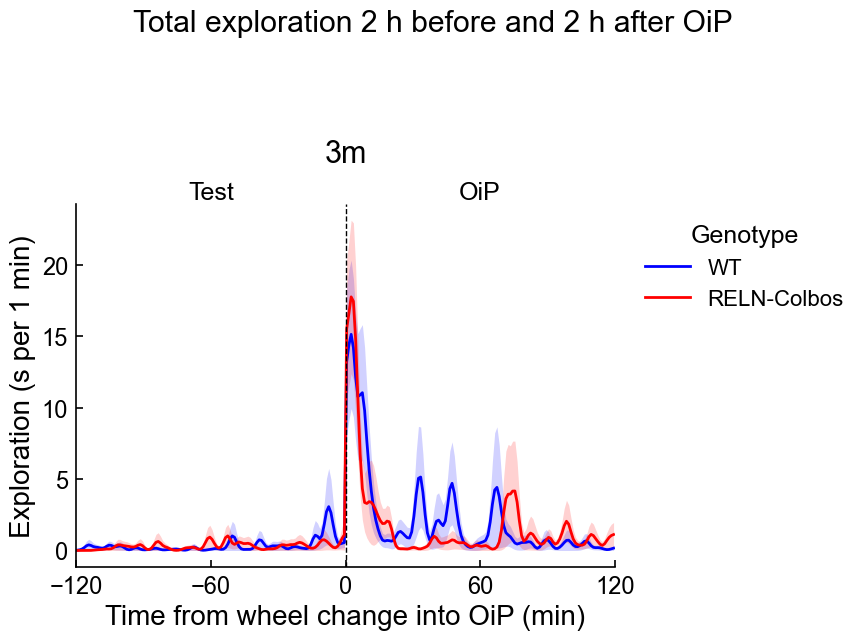

Saved: /Volumes/SWC_SmrtKg2/SmartKages_Nov2025_onwards/NOR_MASTER_RELN-COLBOS/OiP_analysis/Total_exploration_2_h_before_and_8_h_after_OiP.pdf


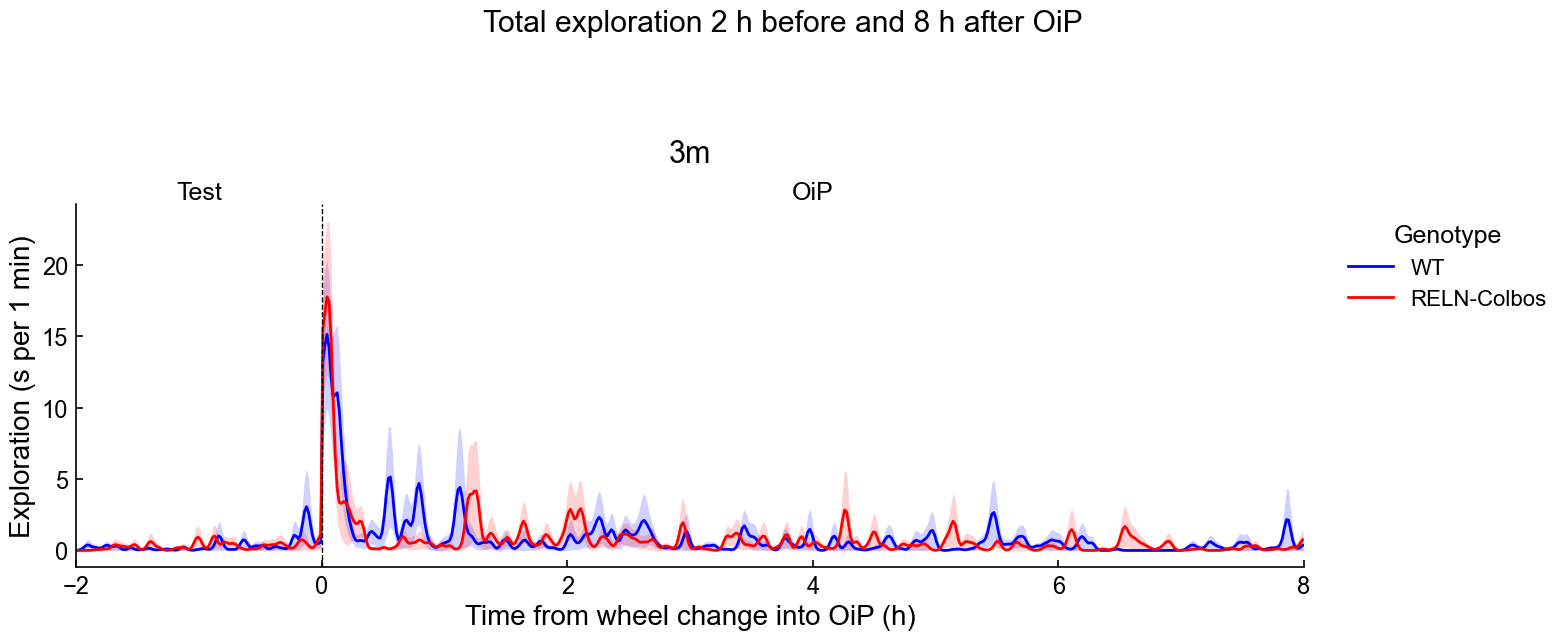

Saved: /Volumes/SWC_SmrtKg2/SmartKages_Nov2025_onwards/NOR_MASTER_RELN-COLBOS/OiP_analysis/Total_exploration_2_h_before_and_24_h_after_OiP.pdf


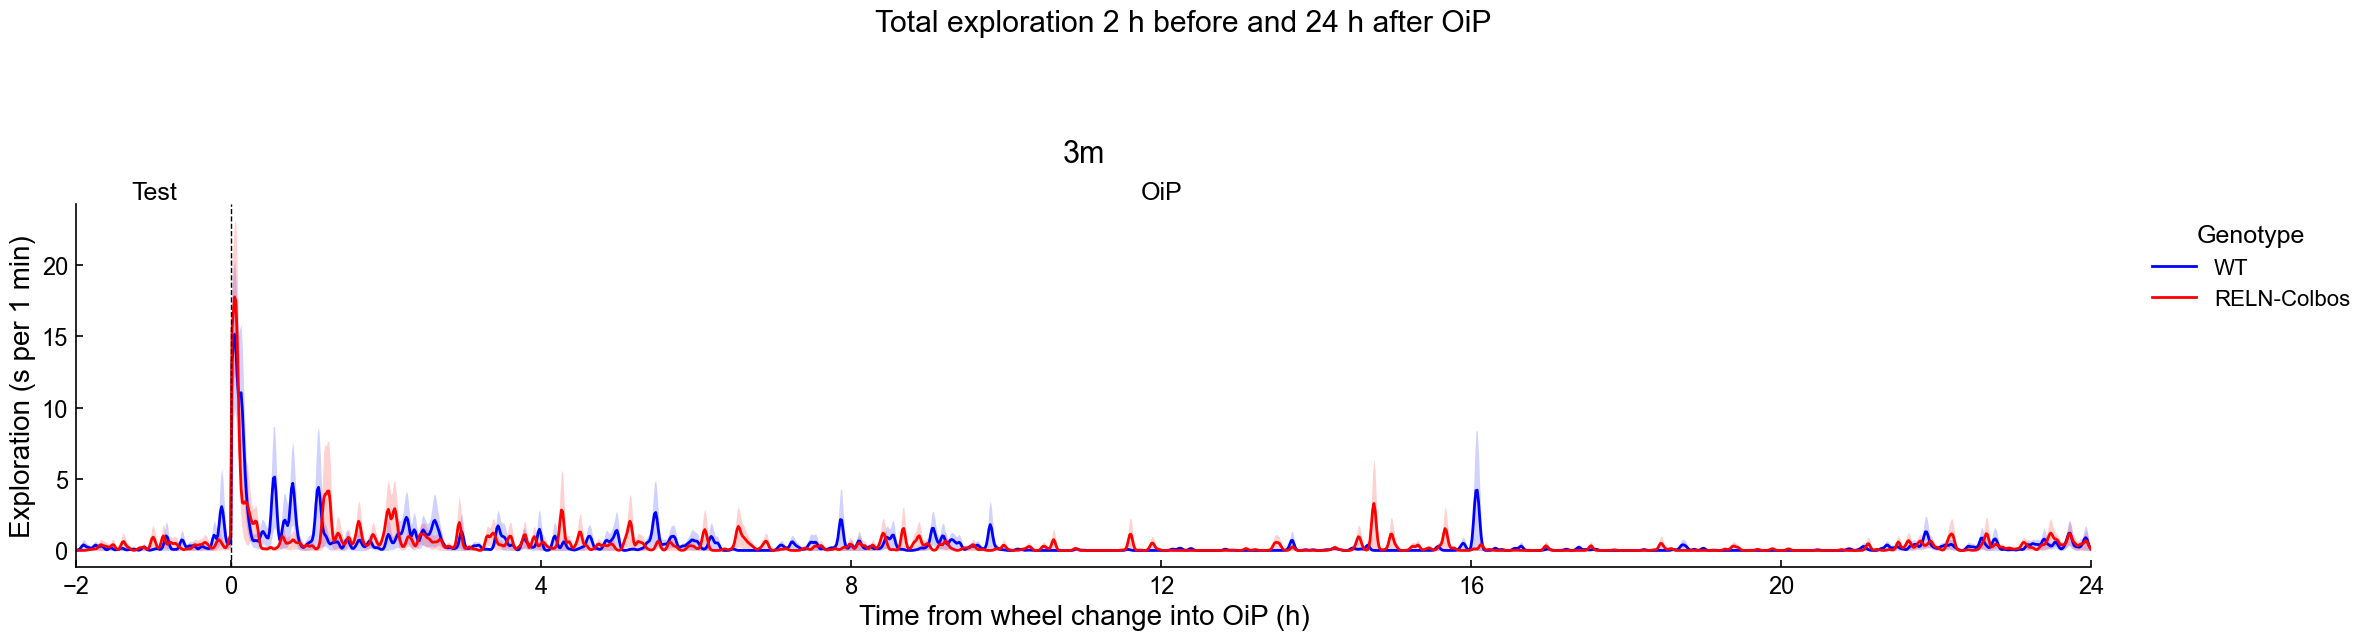

In [139]:
def plot_around_change(per_mouse, value_col, y_label, title, after_min):
    scale, unit, ticks = time_axis(after_min)
    summary = (
        per_mouse[per_mouse["time_bin"].lt(after_min)]
        .groupby(["Age", "Genotype", "time_mid"], as_index=False)
        .agg(mean_value=(value_col, "mean"), sem_value=(value_col, "sem"))
    )
    ages_present = [age for age in AGE_ORDER if age in summary["Age"].unique()]

    # 2 h: ages side by side. Longer windows: ages stacked so each panel can be wide.
    long_window = after_min > 180
    n_ages = len(ages_present)
    nrows, ncols = (n_ages, 1) if long_window else (1, n_ages)
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel_width(after_min) * ncols, 6 * nrows),
                             sharey=True, squeeze=False)
    axes = axes.ravel()

    for ax, age in zip(axes, ages_present):
        for genotype in GENO_ORDER:
            sub = summary[summary["Age"].eq(age) & summary["Genotype"].eq(genotype)].sort_values("time_mid")
            if sub.empty:
                continue
            t = sub["time_mid"].to_numpy()
            x = t / scale
            y = smooth(sub["mean_value"], t)
            sem_values = smooth(sub["sem_value"].fillna(0), t)
            ax.plot(x, y, color=GENO_COLORS[genotype], linewidth=2, label=genotype)
            ax.fill_between(x, y - sem_values, y + sem_values, color=GENO_COLORS[genotype], alpha=0.18, linewidth=0)

        ax.axvline(0, color="black", linestyle="--", linewidth=1)
        ax.text(-BEFORE_MIN / 2 / scale, 1.0, "Test", transform=ax.get_xaxis_transform(), ha="center", va="bottom")
        ax.text(after_min / 2 / scale, 1.0, TARGET_PHASE, transform=ax.get_xaxis_transform(), ha="center", va="bottom")
        ax.set_xlim(-BEFORE_MIN / scale, after_min / scale)
        ax.set_xticks(ticks)
        ax.set_xlabel(f"Time from wheel change into {TARGET_PHASE} ({unit})")
        ax.set_title(age, pad=30)
        format_axes(ax)

    for ax in (axes if long_window else axes[:1]):
        ax.set_ylabel(y_label)
    axes[ncols - 1].legend(frameon=False, title="Genotype", loc="upper left", bbox_to_anchor=(1.02, 1))
    fig.suptitle(title, y=1.08)
    plt.tight_layout()
    save_fig(fig, title.replace(" ", "_"))
    plt.show()


for after_min in AFTER_WINDOWS_MIN:
    plot_around_change(
        oip_binned,
        "total_sec",
        f"Exploration (s per {BIN_MIN} min)",
        f"Total exploration {timepoint_label(BEFORE_MIN)} before and "
        f"{timepoint_label(after_min)} after {TARGET_PHASE}",
        after_min,
    )

## 5. Exploration of each side around the wheel change

One panel per genotype (rows = age). Each line is the mean across mice for one side,
named from the test phase. A mouse that sticks to a side keeps the same line on top
before and after the change.

After the change, in **unchanged OiP** the test-novel object is on the test familiar side (moved),
in **changed OiP** both objects are where they were in test.

Saved: /Volumes/SWC_SmrtKg2/SmartKages_Nov2025_onwards/NOR_MASTER_RELN-COLBOS/OiP_analysis/Exploration_by_side_2_h_before_and_2_h_after_OiP.pdf


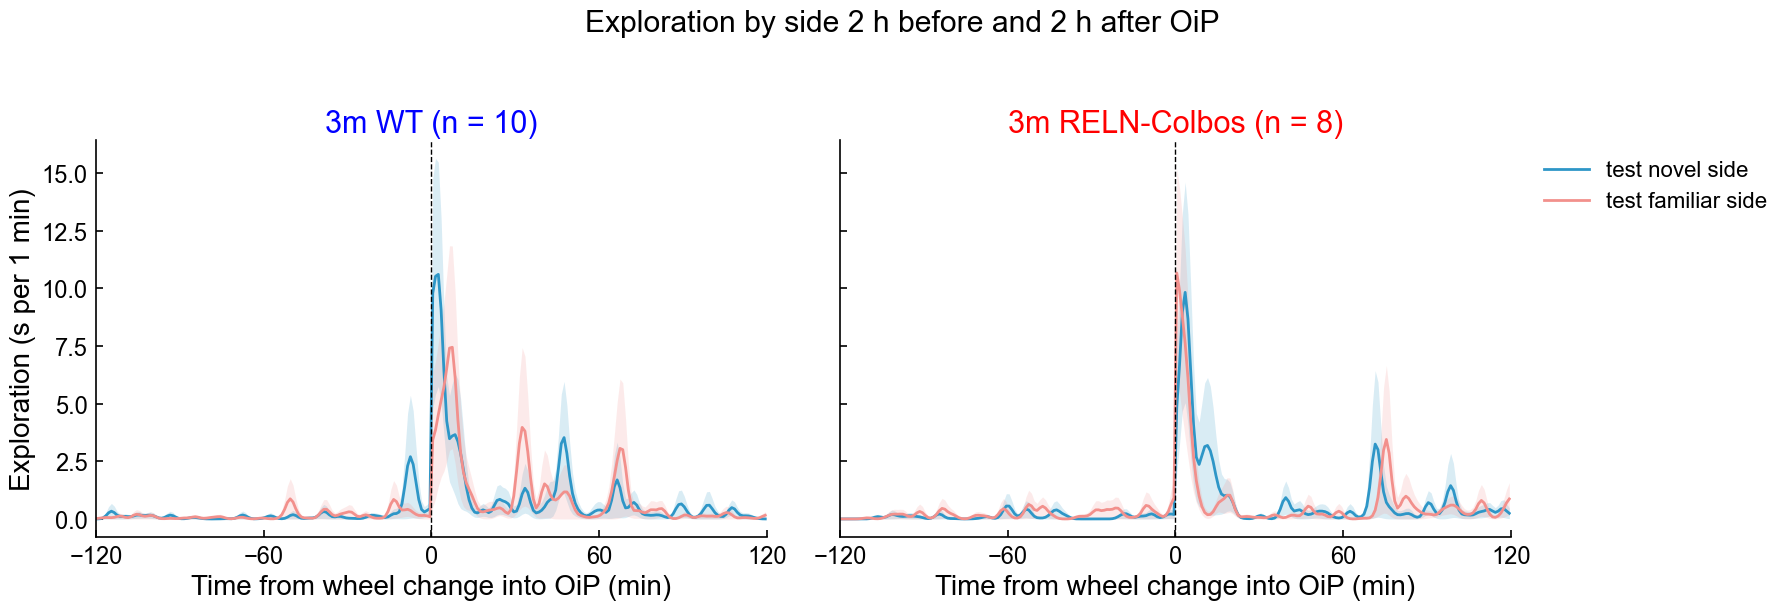

Saved: /Volumes/SWC_SmrtKg2/SmartKages_Nov2025_onwards/NOR_MASTER_RELN-COLBOS/OiP_analysis/Exploration_by_side_2_h_before_and_8_h_after_OiP.pdf


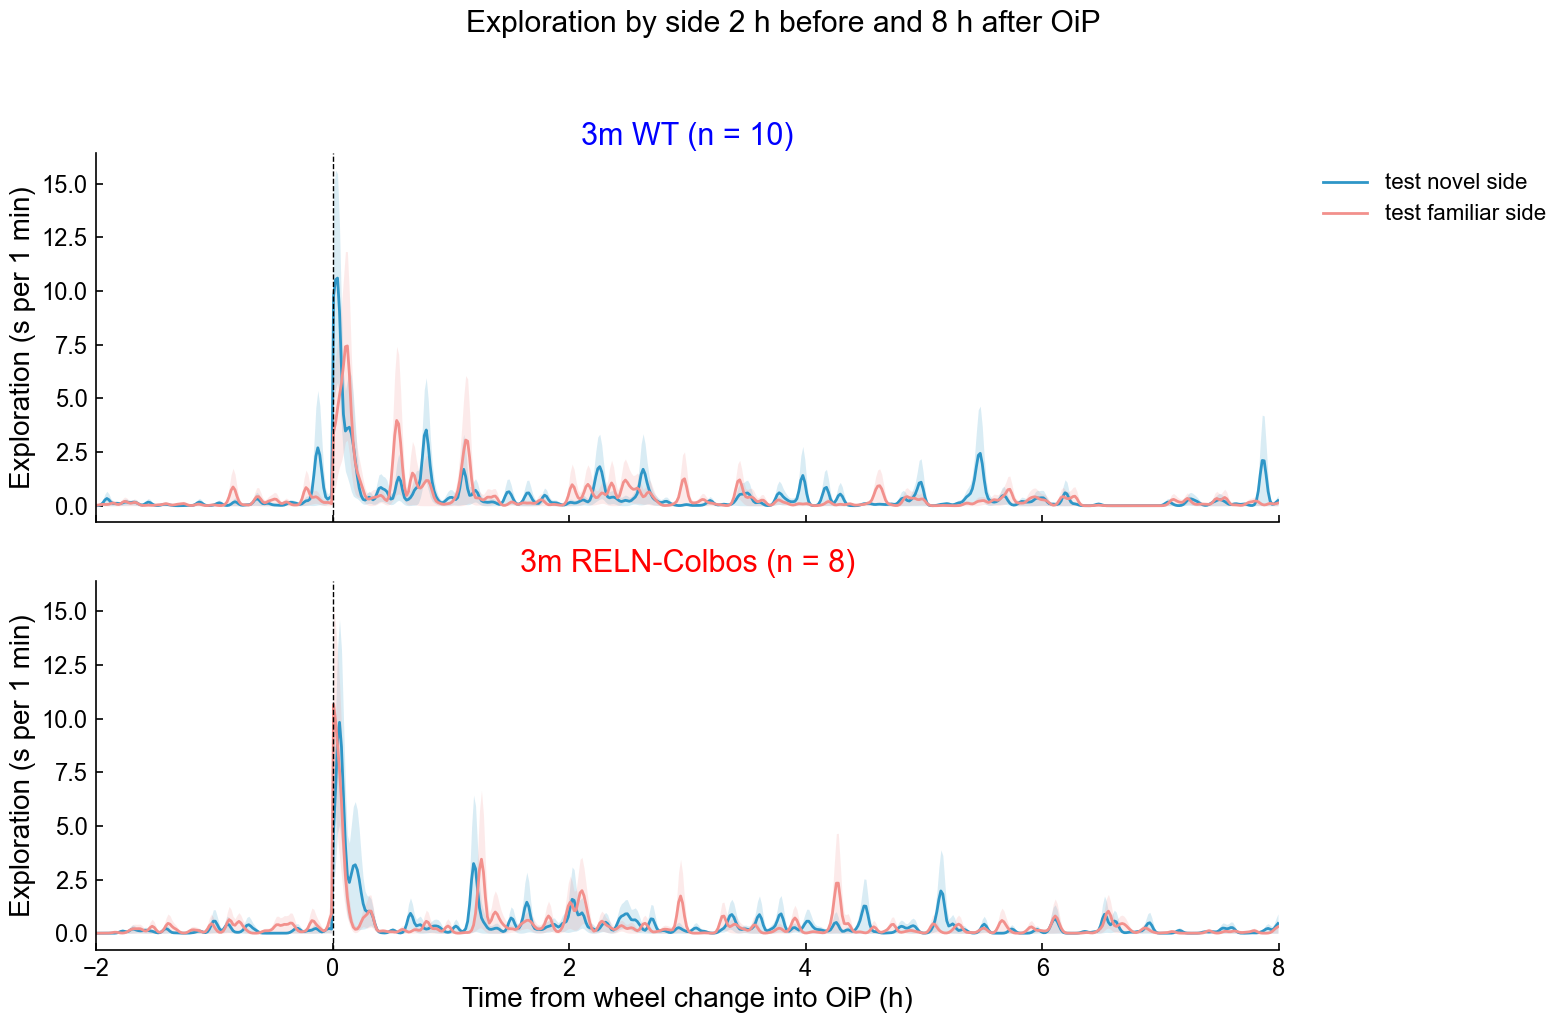

Saved: /Volumes/SWC_SmrtKg2/SmartKages_Nov2025_onwards/NOR_MASTER_RELN-COLBOS/OiP_analysis/Exploration_by_side_2_h_before_and_24_h_after_OiP.pdf


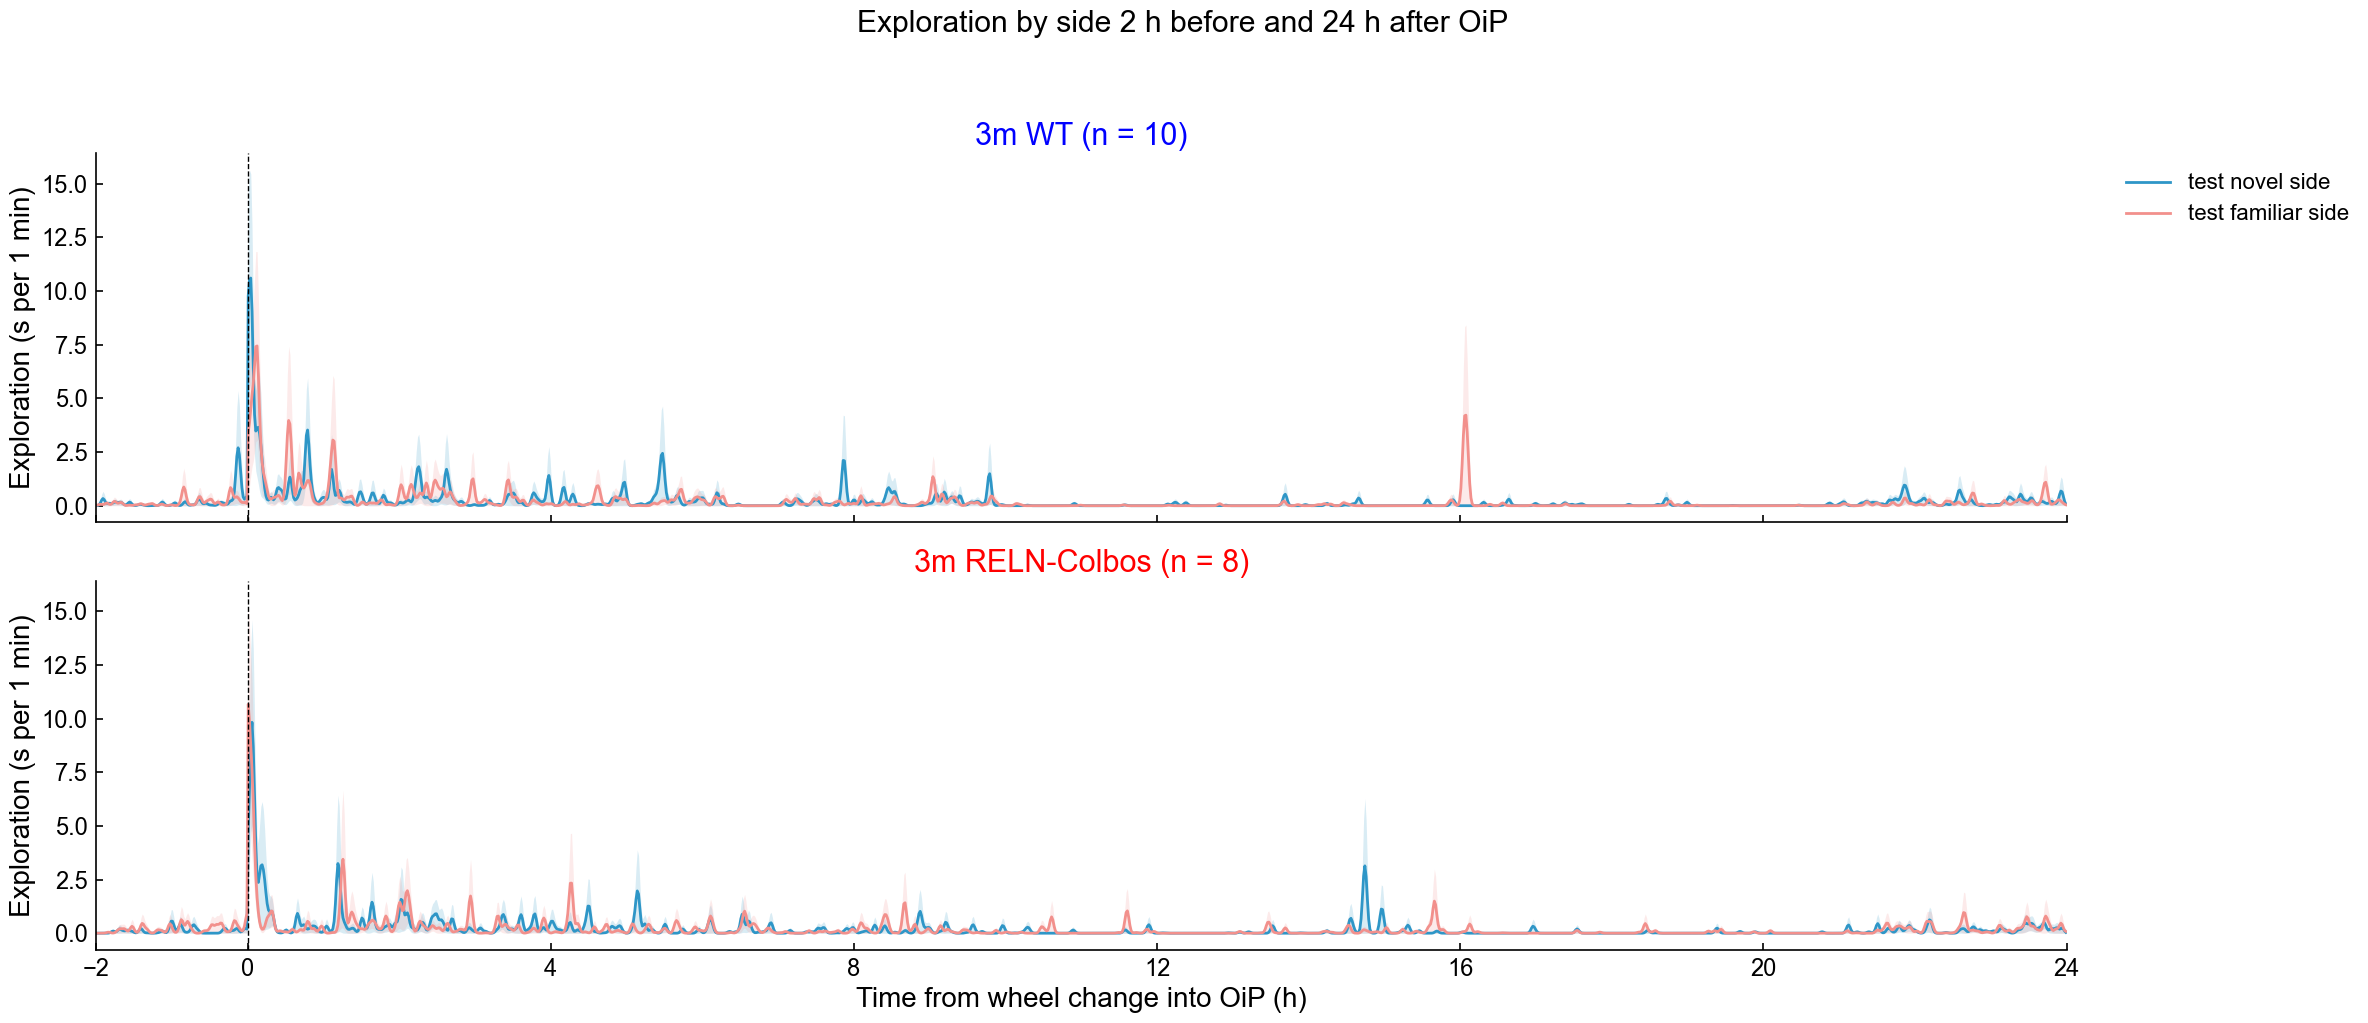

In [140]:
def plot_lines_around_change(per_mouse, lines, colors, title, after_min):
    """One panel per age x genotype; one line per entry in `lines` (label -> column)."""
    scale, unit, ticks = time_axis(after_min)
    per_mouse = per_mouse[per_mouse["time_bin"].lt(after_min)]
    ages_present = [age for age in AGE_ORDER if age in per_mouse["Age"].unique()]
    panels = [(age, genotype) for age in ages_present for genotype in GENO_ORDER]

    # 2 h: genotypes side by side. Longer windows: one wide panel per row.
    long_window = after_min > 180
    nrows, ncols = (len(panels), 1) if long_window else (len(ages_present), len(GENO_ORDER))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(panel_width(after_min) * ncols, (5 if long_window else 6) * nrows),
                             sharex=True, sharey=True, squeeze=False)
    axes = axes.ravel()

    for i, (age, genotype) in enumerate(panels):
            ax = axes[i]
            sub = per_mouse[per_mouse["Age"].eq(age) & per_mouse["Genotype"].eq(genotype)]
            n_mice = sub["MouseSessionID"].nunique()

            for line_label, col in lines.items():
                summary = (
                    sub.groupby("time_mid", as_index=False)
                    .agg(mean_value=(col, "mean"), sem_value=(col, "sem"))
                    .sort_values("time_mid")
                )
                if summary.empty:
                    continue
                t = summary["time_mid"].to_numpy()
                x = t / scale
                y = smooth(summary["mean_value"], t)
                sem_values = smooth(summary["sem_value"].fillna(0), t)
                ax.plot(x, y, color=colors[line_label], linewidth=2, label=line_label)
                ax.fill_between(x, y - sem_values, y + sem_values, color=colors[line_label], alpha=0.18, linewidth=0)

            ax.axvline(0, color="black", linestyle="--", linewidth=1)
            ax.set_xlim(-BEFORE_MIN / scale, after_min / scale)
            ax.set_xticks(ticks)
            ax.set_title(f"{age} {genotype} (n = {n_mice})", color=GENO_COLORS.get(genotype, "black"))
            if i % ncols == 0:
                ax.set_ylabel(f"Exploration (s per {BIN_MIN} min)")
            if i >= len(panels) - ncols:
                ax.set_xlabel(f"Time from wheel change into {TARGET_PHASE} ({unit})")
            format_axes(ax)

    axes[ncols - 1].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1))
    fig.suptitle(title, y=1.03)
    plt.tight_layout()
    save_fig(fig, title.replace(" ", "_"))
    plt.show()


for after_min in AFTER_WINDOWS_MIN:
    plot_lines_around_change(
        oip_binned,
        {"test novel side": "test_novel_side_sec", "test familiar side": "test_familiar_side_sec"},
        SIDE_COLORS,
        f"Exploration by side {timepoint_label(BEFORE_MIN)} before and "
        f"{timepoint_label(after_min)} after {TARGET_PHASE}",
        after_min,
    )

## 6. Per-mouse totals: 2 h before vs 2 h / 8 h / 24 h after

Seconds of exploration in the last 2 h of test (`before_2h`) and the first 2 h, 8 h and 24 h of OiP
(`after_2h`, `after_8h`, `after_24h`). The after windows overlap (the first 2 h are part of 8 h and 24 h).

In [141]:
MOUSE_COLS = ["MouseSessionID", "KageID", "Cohort", "Age", "Genotype"]

total_windows = {f"before_{timepoint_label(BEFORE_MIN).replace(' ', '')}": aligned["rel_min"].lt(0)}
for after_min in AFTER_WINDOWS_MIN:
    total_windows[f"after_{timepoint_label(after_min).replace(' ', '')}"] = aligned["rel_min"].between(0, after_min - 1)

oip_totals = None
for window_name, in_window in total_windows.items():
    part = (
        aligned[in_window]
        .groupby(MOUSE_COLS)[VALUE_COLS]
        .sum()
        .add_suffix(f"_{window_name}")
        .reset_index()
    )
    oip_totals = part if oip_totals is None else oip_totals.merge(part, on=MOUSE_COLS, how="outer")

oip_totals.head()

,MouseSessionID,KageID,Cohort,Age,Genotype,total_sec_before_2h,test_novel_side_sec_before_2h,test_familiar_side_sec_before_2h,total_sec_after_2h,test_novel_side_sec_after_2h,test_familiar_side_sec_after_2h,total_sec_after_8h,test_novel_side_sec_after_8h,test_familiar_side_sec_after_8h,total_sec_after_24h,test_novel_side_sec_after_24h,test_familiar_side_sec_after_24h
0,2026-01-Jan-Feb_RELN-COLBOS_Coh2_Kage1,Kage1,2026-01-Jan-Feb_RELN-COLBOS_Coh2,3m,RELN-Colbos,19.0,9.5,9.5,201.0,90.5,110.5,356.0,174.5,181.5,437.0,217.5,219.5
1,2026-01-Jan-Feb_RELN-COLBOS_Coh2_Kage11,Kage11,2026-01-Jan-Feb_RELN-COLBOS_Coh2,3m,WT,17.0,10.0,7.0,137.0,26.0,111.0,250.0,76.5,173.5,275.0,87.0,188.0
2,2026-01-Jan-Feb_RELN-COLBOS_Coh2_Kage12,Kage12,2026-01-Jan-Feb_RELN-COLBOS_Coh2,3m,WT,5.5,3.5,2.0,292.0,114.0,178.0,616.0,287.0,329.0,708.5,340.5,368.0
3,2026-01-Jan-Feb_RELN-COLBOS_Coh2_Kage13,Kage13,2026-01-Jan-Feb_RELN-COLBOS_Coh2,3m,WT,73.0,28.5,44.5,286.5,135.5,151.0,441.5,203.5,238.0,696.5,346.5,350.0
4,2026-01-Jan-Feb_RELN-COLBOS_Coh2_Kage14,Kage14,2026-01-Jan-Feb_RELN-COLBOS_Coh2,3m,RELN-Colbos,26.5,11.5,15.0,138.0,56.5,81.5,296.0,117.0,179.0,424.0,171.0,253.0


## 7. Individual kages around the wheel change (unfinished)

** The following analysis is unfinihsed and should be treated as exploratory. 

The idea: generate a per-kage report so that it is easier to visualise/ qc per kage performance. 

One panel per kage, all panels on the same axes, so a kage that explores more than the others stands out.
Kages are ordered by genotype, cohort and kage number, and labelled with a short cohort name (`COHORT_LABELS`).
The window runs to `KAGE_AFTER_MIN` minutes after the wheel change into OiP. Minutes after a kage's next
wheel change are missing, not 0: lines stop there.

- **7.1 Exploration over time**: from 2 h before the wheel change, smoothed with `SMOOTH_SIGMA`
- **7.2 Cumulative exploration**: running total from the wheel change, not smoothed

A per-kage PDF report (one page per kage) is in `SmartKage_NOR_OiP_kage_report.ipynb`.

In [142]:
KAGE_AFTER_MIN = 1440     # plot this many minutes after the wheel change (120, 480 or 1440)
COHORT_LABELS = {         # short cohort names for the panel titles
    "2025-07-July_OiP_CohortC": "CohC",
    "2025-08-Aug_OiP_CohortD": "CohD",
}


def make_kage_table(per_mouse):
    """One row per kage, in plotting order, with a short label such as 'CohD Kage7'."""
    kages = per_mouse[MOUSE_COLS].drop_duplicates().copy()
    kages["kage_number"] = kages["KageID"].str.extract(r"(\d+)", expand=False).astype(int)
    kages["kage_label"] = kages["Cohort"].map(COHORT_LABELS).fillna(kages["Cohort"]) + " " + kages["KageID"]
    kages["genotype_rank"] = kages["Genotype"].map({g: i for i, g in enumerate(GENO_ORDER)})
    return (
        kages[kages["Genotype"].isin(GENO_ORDER)]
        .sort_values(["Age", "genotype_rank", "Cohort", "kage_number"])
        .reset_index(drop=True)
    )


def plot_kage_panels(per_mouse, kages, age, after_min, cumulative=False, n_cols=5):
    """One panel per kage. cumulative=False: exploration from 2 h before the wheel change (smoothed).
    cumulative=True: running total from the wheel change (not smoothed)."""
    kages = kages[kages["Age"].eq(age)]
    scale, unit, ticks = time_axis(after_min)
    start_min = 0 if cumulative else -BEFORE_MIN
    per_mouse = per_mouse[per_mouse["time_bin"].between(start_min, after_min - 1)]

    n_rows = int(np.ceil(len(kages) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3 * n_rows), sharex=True, sharey=True, squeeze=False)
    axes = axes.ravel()

    for ax, (_, kage) in zip(axes, kages.iterrows()):
        rows = per_mouse[per_mouse["MouseSessionID"].eq(kage["MouseSessionID"])].sort_values("time_mid")
        t = rows["time_mid"].to_numpy()
        y = rows["total_sec"].cumsum() if cumulative else smooth(rows["total_sec"], t)
        color = GENO_COLORS[kage["Genotype"]]
        ax.plot(t / scale, y, color=color, linewidth=1.3)
        if not cumulative:
            ax.axvline(0, color="black", linestyle="--", linewidth=1)
        ax.set_xlim(start_min / scale, after_min / scale)
        ax.set_xticks([x for x in ticks if x >= start_min / scale])
        ax.set_title(kage["kage_label"], color=color, fontsize=16)
        format_axes(ax)

    for ax in axes[len(kages):]:
        ax.set_visible(False)

    fig.supxlabel(f"Time from wheel change into {TARGET_PHASE} ({unit})")
    fig.supylabel("Cumulative exploration (s)" if cumulative else f"Exploration (s per {BIN_MIN} min)")
    title = f"{'Cumulative exploration' if cumulative else 'Exploration'} per kage ({age})"
    fig.suptitle(title)
    plt.tight_layout()
    save_fig(fig, title.replace(" ", "_"))
    plt.show()


kage_table = make_kage_table(oip_binned)
display(kage_table.groupby(["Age", "Genotype", "Cohort"], as_index=False).size())

,Age,Genotype,Cohort,size
0,3m,RELN-Colbos,2026-01-Jan-Feb_RELN-COLBOS_Coh2,5
1,3m,RELN-Colbos,new_2025-11-Nov-Dec_RELN-COLBOS_Coh1,3
2,3m,WT,2026-01-Jan-Feb_RELN-COLBOS_Coh2,7
3,3m,WT,new_2025-11-Nov-Dec_RELN-COLBOS_Coh1,3


### 7.1 Exploration over time, one panel per kage

Saved: /Volumes/SWC_SmrtKg2/SmartKages_Nov2025_onwards/NOR_MASTER_RELN-COLBOS/OiP_analysis/Exploration_per_kage_(3m).pdf


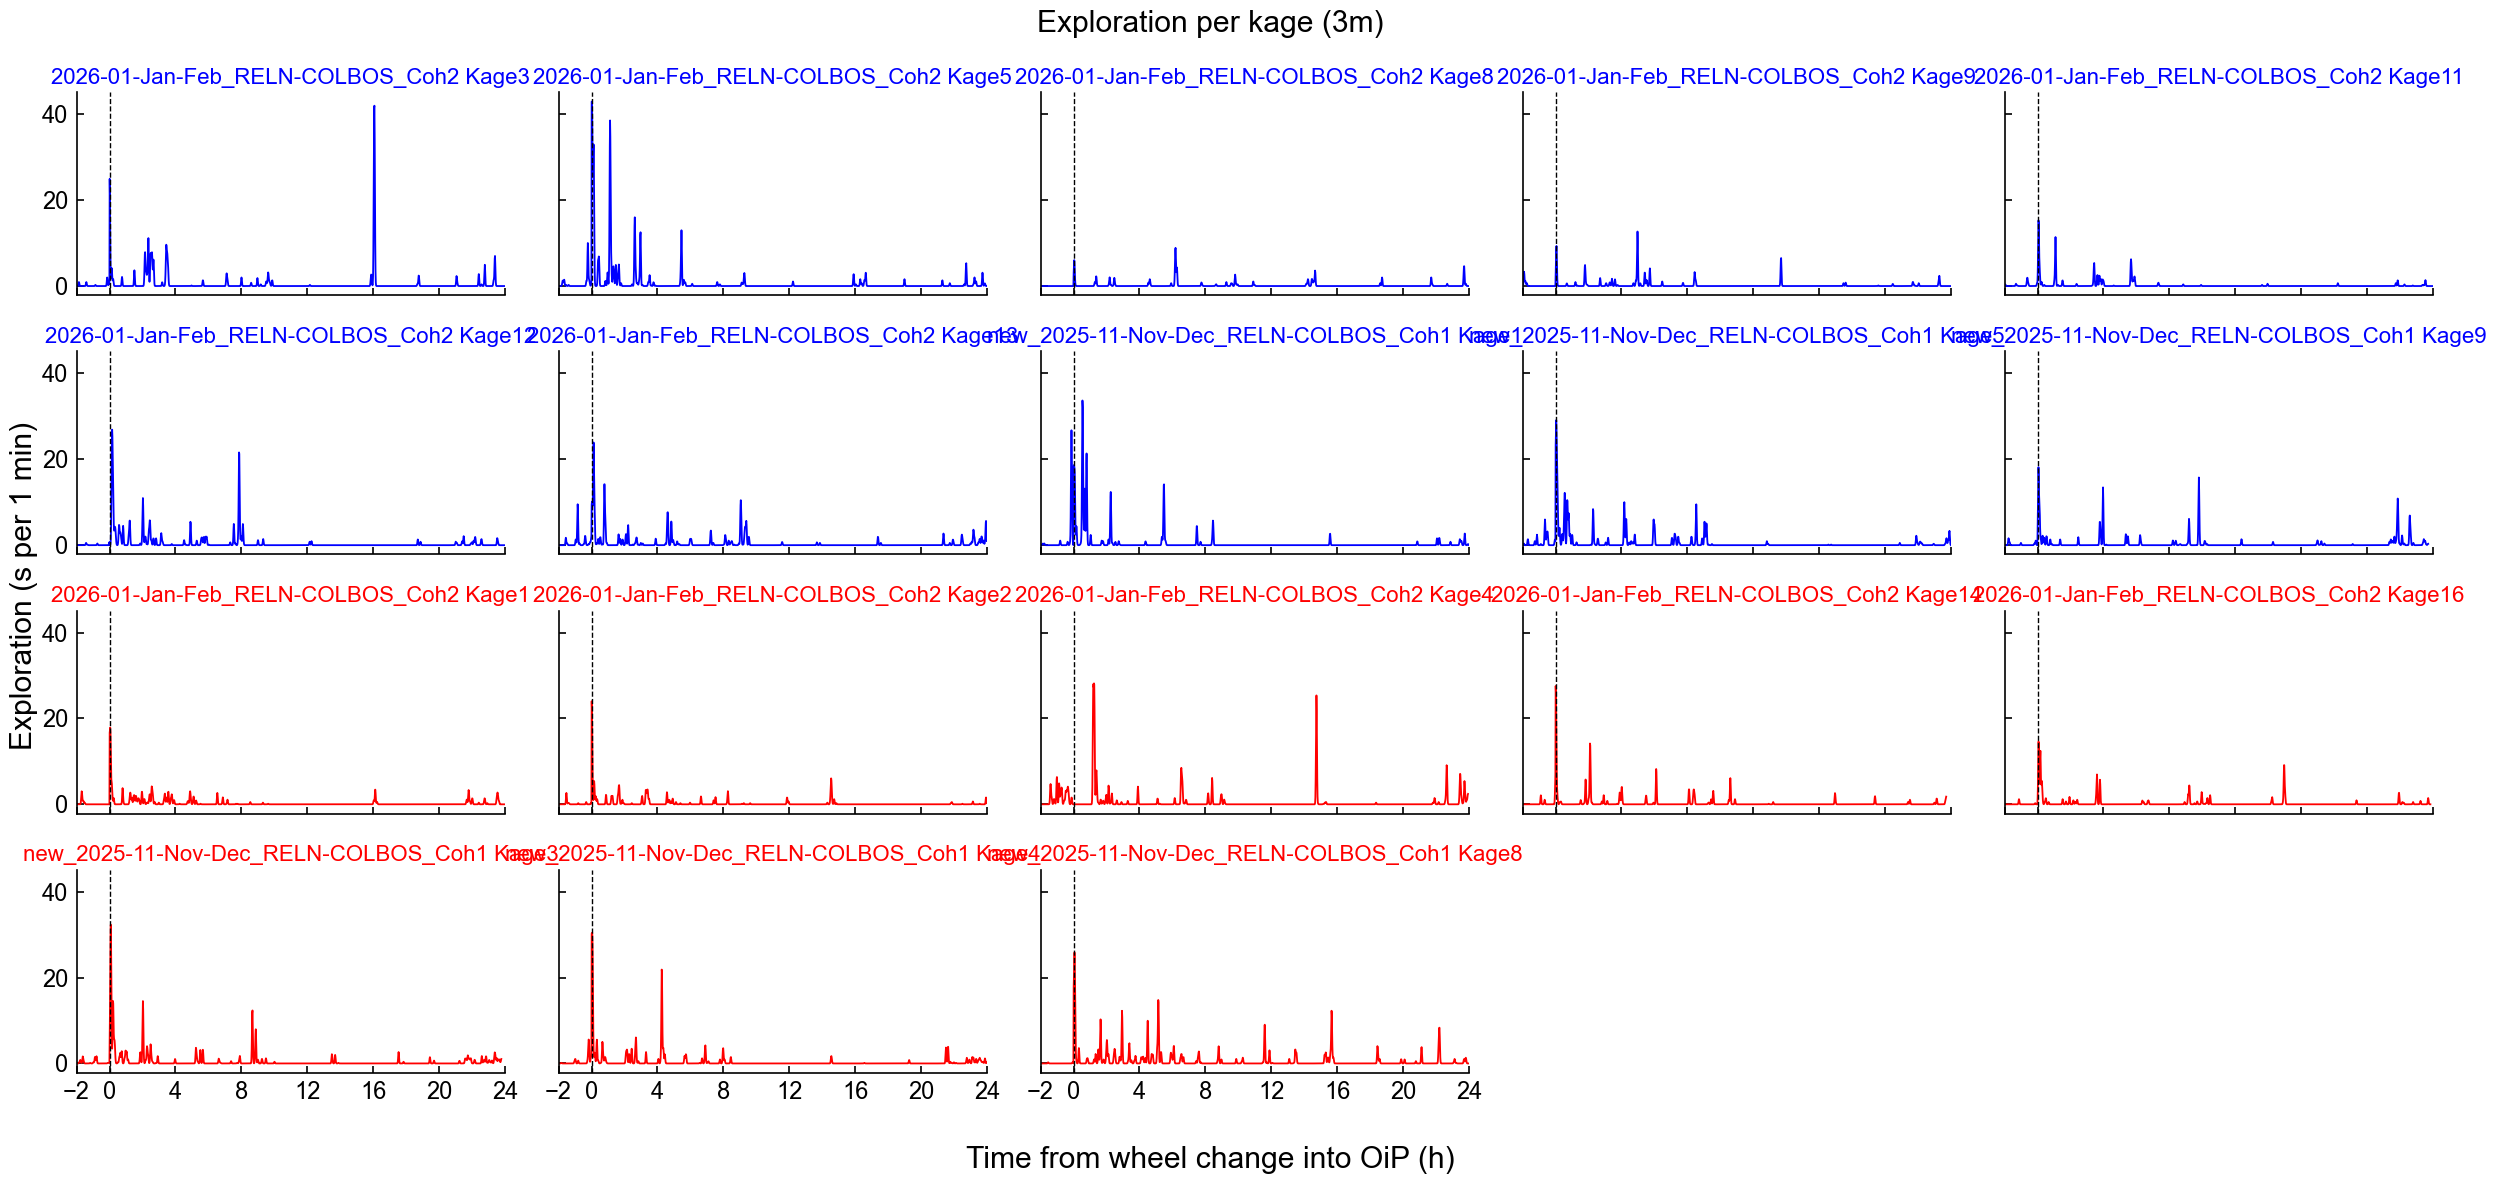

In [143]:
for age in AGE_ORDER:
    plot_kage_panels(oip_binned, kage_table, age, KAGE_AFTER_MIN)

### 7.2 Cumulative exploration, one panel per kage

Saved: /Volumes/SWC_SmrtKg2/SmartKages_Nov2025_onwards/NOR_MASTER_RELN-COLBOS/OiP_analysis/Cumulative_exploration_per_kage_(3m).pdf


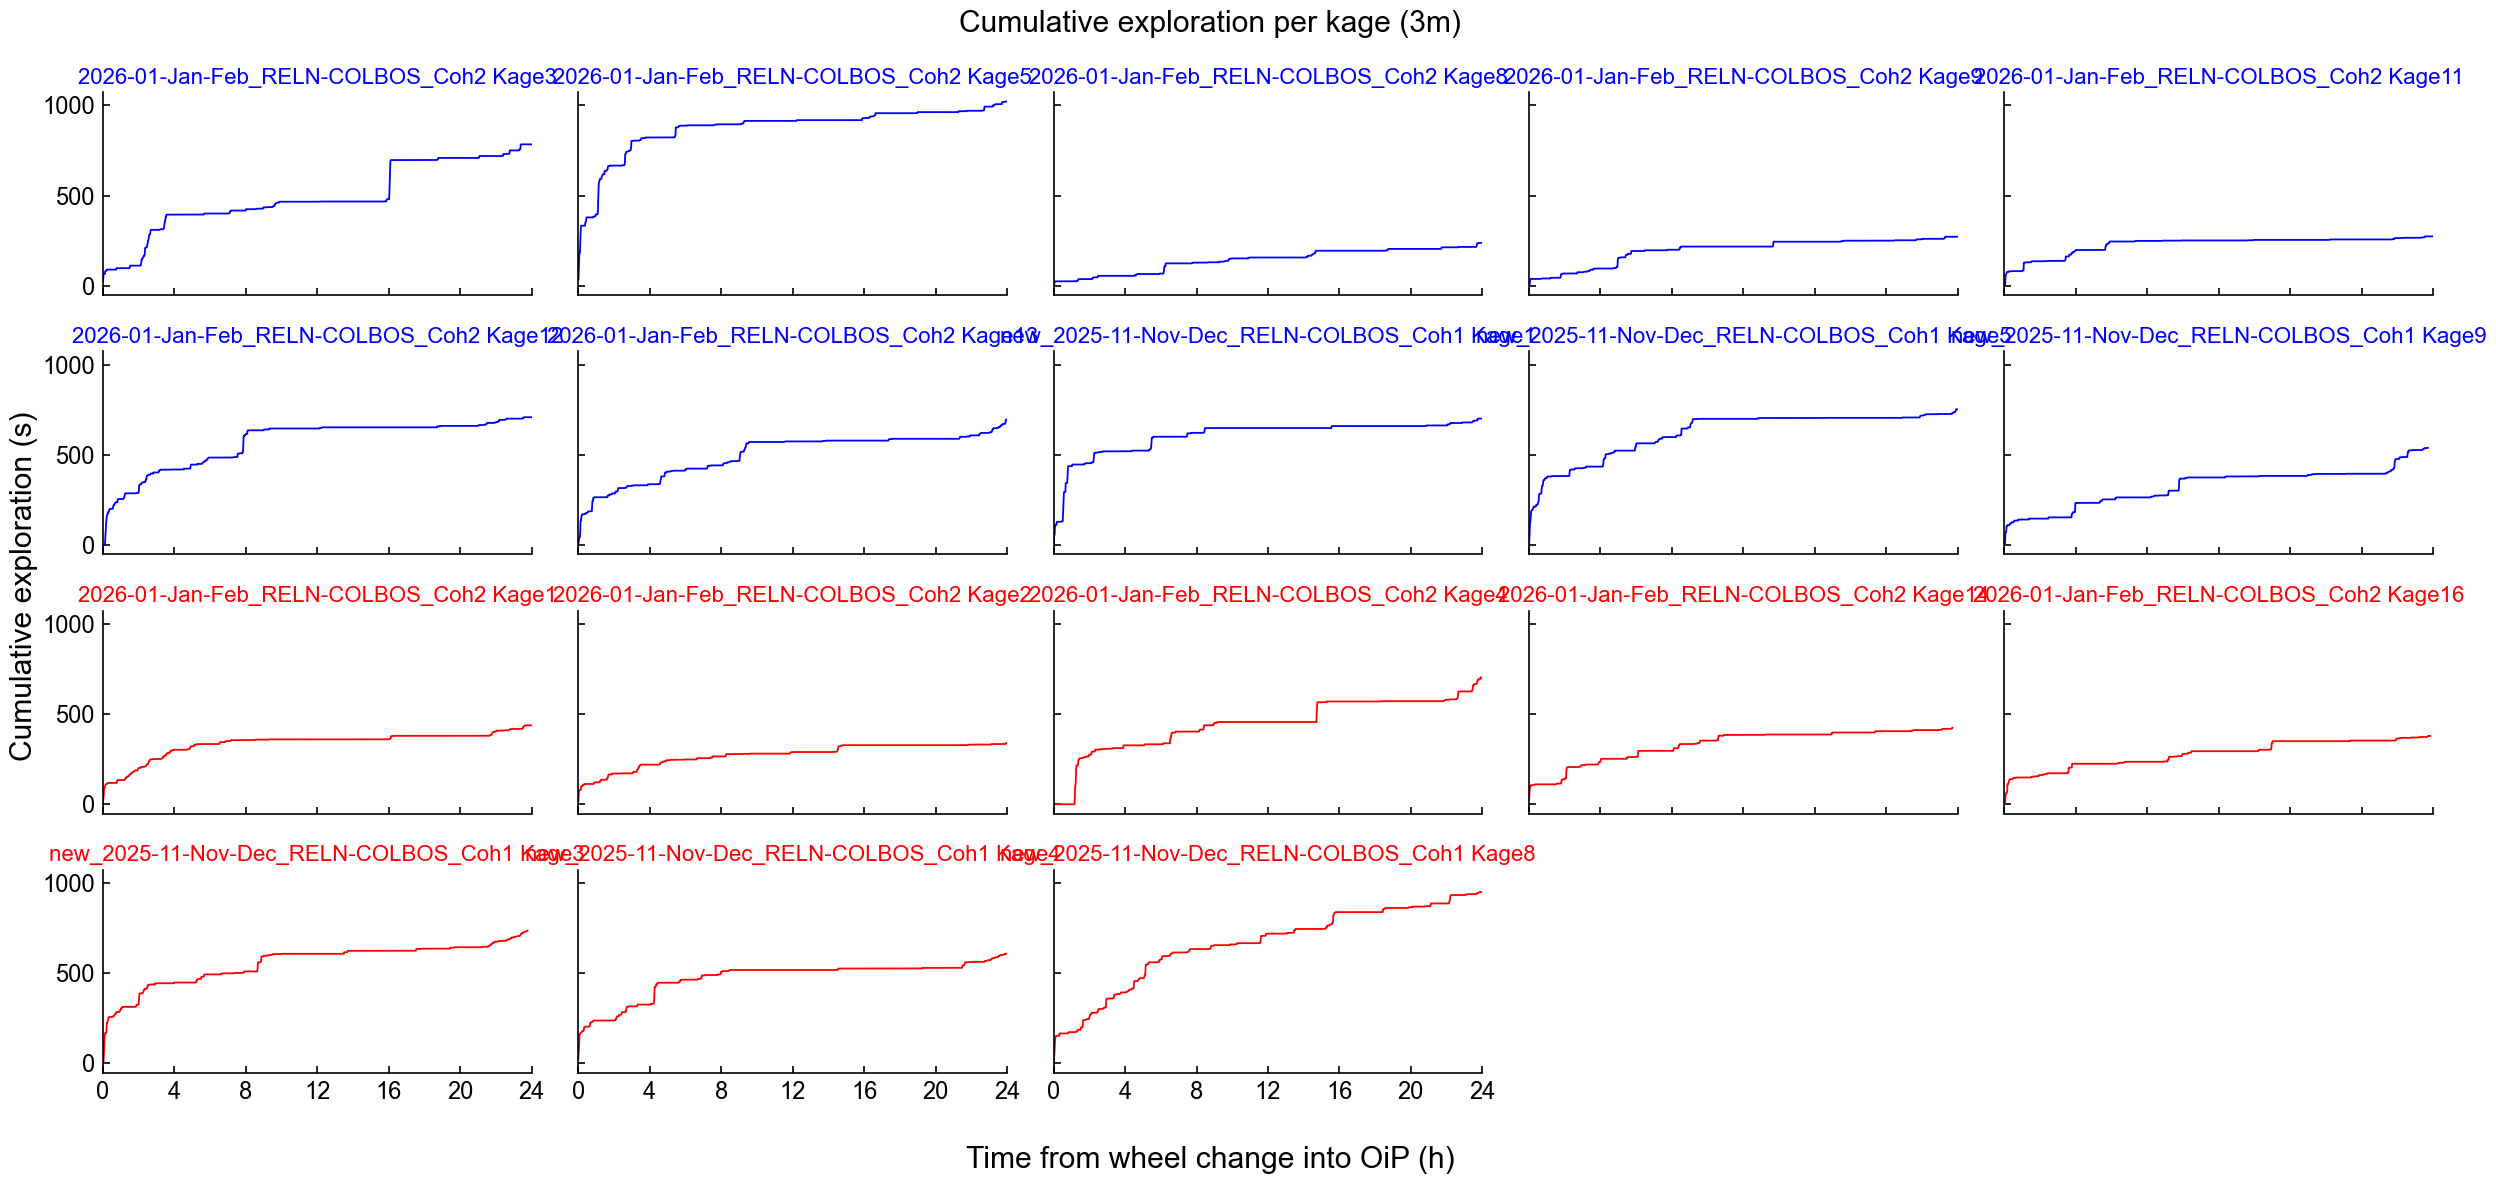

In [144]:
for age in AGE_ORDER:
    plot_kage_panels(oip_binned, kage_table, age, KAGE_AFTER_MIN, cumulative=True)

## 8. Save tables (only when `SAVE_OUTPUTS = True`)

Files written to `OIP_OUTPUT`:
- `OiP_aligned_<BIN_MIN>min_bins_per_mouse.csv`: sections 4–5, per mouse and bin
- `OiP_before_after_totals_per_mouse.csv`: section 6

In [145]:
if SAVE_OUTPUTS:
    OIP_OUTPUT.mkdir(exist_ok=True)
    oip_binned.to_csv(OIP_OUTPUT / f"OiP_aligned_{BIN_MIN}min_bins_per_mouse.csv", index=False)
    oip_totals.to_csv(OIP_OUTPUT / "OiP_before_after_totals_per_mouse.csv", index=False)
    print("Saved tables to:", OIP_OUTPUT)
else:
    print("SAVE_OUTPUTS is False: nothing saved.")

Saved tables to: /Volumes/SWC_SmrtKg2/SmartKages_Nov2025_onwards/NOR_MASTER_RELN-COLBOS/OiP_analysis
